
#  Notebook 3: DenseNet-121 — Binary Classifier

## Why DenseNet-121?
DenseNet-121 (Densely Connected Convolutional Network) is a landmark
architecture in medical imaging:
- Every layer receives feature maps from **all previous layers** (dense connections)
- This reuse of features prevents information bottlenecks
- Specifically validated in published dermatology papers (Stanford 2017 Nature paper)
- Drastically outperforms standard CNNs on fine-grained lesion classification

It brings **complementary features** to EfficientNetV2-S in the ensemble:
- EfficientNet focuses on efficiency and fine textures
- **DenseNet focuses on deep multi-scale feature reuse** — ideal for subtle edge details

## Architecture Summary
- Backbone: `densenet121` from timm (ImageNet pretrained)
- Custom head: BatchNorm → Dropout(0.4) → Linear(256) → ReLU → Linear(1)
- Loss: Focal Loss (same as Notebook 2)
- Optimizer: AdamW + CosineAnnealingLR

In [1]:

# ── CODE CELL 1: Install & Import ─────────────────────────────────────
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import torchvision.transforms as T
import timm

from sklearn.metrics import (roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️  Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

🖥️  Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB


## Configuration

In [2]:


# ── CODE CELL 2: Hyperparameter Config ────────────────────────────────
INPUT_CSV_DIR = '/kaggle/input/notebooks/nandini143/data-preparation'
OUTPUT_DIR    = '/kaggle/working/'

IMG_SIZE      = 384
BATCH_SIZE    = 16
NUM_EPOCHS    = 30
LR            = 5e-5       # Softer LR — DenseNet converges more stably at lower rates
WEIGHT_DECAY  = 1e-2
PATIENCE      = 7
WARMUP_EPOCHS = 3      # Extra warmup epoch — more head stabilisation before backbone unfreezes
MODEL_NAME    = 'densenet121'
SAVE_PATH     = os.path.join(OUTPUT_DIR, 'densenet121_best.pth')

print("=" * 55)
print(f"  Model         : {MODEL_NAME}")
print(f"  Image Size    : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch Size    : {BATCH_SIZE}")
print(f"  Max Epochs    : {NUM_EPOCHS}")
print(f"  LR            : {LR}  |  WD: {WEIGHT_DECAY}")
print(f"  Warmup Epochs : {WARMUP_EPOCHS} (backbone frozen during warmup)")
print("=" * 55)
# ── Multi-Modal Metadata Config (Phase 2) ────────────────────────────────
META_DIM    = 11   # age_norm(1) + sex_encoded(1) + site_one_hot(9)
META_HIDDEN = 32   # Hidden units in Tabular MLP branch
USE_CUTMIX  = True
CUTMIX_PROB = 0.3


  Model         : densenet121
  Image Size    : 384x384
  Batch Size    : 16
  Max Epochs    : 30
  LR            : 5e-05  |  WD: 0.01
  Warmup Epochs : 3 (backbone frozen during warmup)


## Dataset & Augmentation
Identical augmentation pipeline to Notebook 2 to ensure
a fair comparison between architectures.

In [3]:
# ── CODE CELL: Multi-Modal Dataset ────────────────────────────────────────────
METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown'
]

class ISICDataset(Dataset):
    """Multi-Modal: returns (image_tensor, metadata_tensor, label_tensor)"""
    def __init__(self, df, transform, is_train=True):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
        self.is_train  = is_train
        self.meta_cols = [c for c in METADATA_COLS if c in df.columns]
        if not self.meta_cols:
            print("  WARNING: No metadata columns found! Using zero vectors.")
        else:
            print(f"  Dataset: {len(df)} rows | {len(self.meta_cols)} metadata features")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        if self.meta_cols:
            meta = torch.tensor(row[self.meta_cols].values.astype('float32'), dtype=torch.float32)
        else:
            meta = torch.zeros(META_DIM, dtype=torch.float32)
        return image, meta, label


In [4]:
# ── CODE CELL: Augmentation (CLAHE + CoarseDropout) ───────────────────────────
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_albu = A.Compose([
    A.Resize(int(IMG_SIZE * 1.12), int(IMG_SIZE * 1.12)),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.2, rotate_limit=15, p=0.5),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.4),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, min_holes=1, fill_value=0, p=0.4),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
val_albu = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

class AlbuTransform:
    def __init__(self, pipeline):
        self.pipeline = pipeline
    def __call__(self, pil_img):
        img_np = np.array(pil_img)
        return self.pipeline(image=img_np)['image']

train_transforms = AlbuTransform(train_albu)
val_transforms   = AlbuTransform(val_albu)
print("Transforms: CLAHE + CoarseDropout added (Phase 2)")


Transforms: CLAHE + CoarseDropout added (Phase 2)


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_23/2186101792.py:18: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, min_holes=1, fill_value=0, p=0.4),


In [5]:
# ── CODE CELL 5: Load Data (UPDATED) ───────────────────────────────────

# Load the CSVs
train_df = pd.read_csv(f'{INPUT_CSV_DIR}/binary_train.csv')
val_df   = pd.read_csv(f'{INPUT_CSV_DIR}/binary_val.csv')
test_df  = pd.read_csv(f'{INPUT_CSV_DIR}/binary_test.csv')

# 🔧 THE FIX: Dynamically update the file paths in memory
# Swap the old Notebook 1 path for the new Notebook 2 input path
OLD_PATH = '/kaggle/working/preprocessed/'
NEW_PATH = f'{INPUT_CSV_DIR}/preprocessed/'

train_df['image_path'] = train_df['image_path'].str.replace(OLD_PATH, NEW_PATH)
val_df['image_path']   = val_df['image_path'].str.replace(OLD_PATH, NEW_PATH)
test_df['image_path']  = test_df['image_path'].str.replace(OLD_PATH, NEW_PATH)

# Proceed with Dataset initialization using the corrected dataframes
train_dataset = ISICDataset(train_df, train_transforms, is_train=True)
val_dataset   = ISICDataset(val_df,   val_transforms,   is_train=False)
test_dataset  = ISICDataset(test_df,  val_transforms,   is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"\n📦 DataLoaders ready:")
print(f"   Train batches : {len(train_loader):>4} ({len(train_dataset):,} images)")
print(f"   Val batches   : {len(val_loader):>4} ({len(val_dataset):,} images)")
print(f"   Test batches  : {len(test_loader):>4} ({len(test_dataset):,} images)")
print("DataLoaders ready (multi-modal: 3-item batches: image, meta, label)")


  Dataset: 20264 rows | 11 metadata features
  Dataset: 2533 rows | 11 metadata features
  Dataset: 2534 rows | 11 metadata features

📦 DataLoaders ready:
   Train batches : 1267 (20,264 images)
   Val batches   :  159 (2,533 images)
   Test batches  :  159 (2,534 images)
DataLoaders ready (multi-modal: 3-item batches: image, meta, label)


## Focal Loss & DenseNet-121 Model
Same Focal Loss as Notebook 2, ensuring consistent training conditions
across the ensemble members.

In [6]:
# ── CODE CELL 5: Focal Loss ────────────────────────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.35, gamma=2.0, label_smoothing=0.02):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        # Apply gentle label smoothing (0.02) to prevent overconfidence
        if self.label_smoothing > 0:
            targets = targets * (1 - self.label_smoothing) + 0.5 * self.label_smoothing
        bce   = nn.functional.binary_cross_entropy_with_logits(
                    logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t   = probs * targets + (1 - probs) * (1 - targets)
        alpha = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal = alpha * (1 - p_t) ** self.gamma * bce
        return focal.mean()


## Phase 2: Multi-Modal Architecture & CutMix

In [7]:
# ── PHASE 2: Multi-Modal Architecture (FIXED) ─────────────────────────────────
import timm

class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.BatchNorm1d(hidden_dim),
            nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim), nn.GELU(),
        )
    def forward(self, x): 
        return self.net(x)

class MultiModalDenseNet(nn.Module):
    def __init__(self, backbone_name, meta_dim=11, meta_hidden=32, dropout=0.5, pretrained=True):
        super().__init__()
        self.backbone  = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
        
        # ✅ FIXED: Added self. to correctly reference the backbone
        img_feat_dim   = self.backbone.num_features
        
        self.meta_mlp  = TabularMLP(meta_dim, meta_hidden, meta_hidden)
        fusion_dim     = img_feat_dim + meta_hidden
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256), nn.GELU(),
            nn.Dropout(dropout * 0.5), nn.Linear(256, 1)
        )
    def forward(self, images, meta):
        img_feats  = self.backbone(images)
        meta_feats = self.meta_mlp(meta)
        fused      = torch.cat([img_feats, meta_feats], dim=1)
        return self.head(fused).squeeze(1)

def freeze_backbone(m):
    for p in m.backbone.parameters(): p.requires_grad = False

def unfreeze_all(m):
    for p in m.parameters(): p.requires_grad = True

if 'model' in locals(): del model
model = MultiModalDenseNet(backbone_name=MODEL_NAME, meta_dim=META_DIM,
                                meta_hidden=META_HIDDEN, pretrained=True).to(DEVICE)
freeze_backbone(model)

hp = sum(p.numel() for p in model.parameters() if p.requires_grad)
tp = sum(p.numel() for p in model.parameters())
print(f"✅ MultiModal DenseNet: total={tp:,} | trainable (warmup)={hp:,}")

model.safetensors:   0%|          | 0.00/32.3M [00:00<?, ?B/s]

✅ MultiModal DenseNet: total=7,226,721 | trainable (warmup)=272,865


In [8]:
# ── PHASE 2: CutMix + MixUp helpers ──────────────────────────────────────────
import numpy as np

def rand_bbox(size, lam):
    W, H  = size[2], size[3]
    cut_r = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_r), int(H * cut_r)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W); x2 = np.clip(cx + cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H); y2 = np.clip(cy + cut_h // 2, 0, H)
    return x1, y1, x2, y2

def apply_cutmix_or_mixup(images, labels, meta, prob=0.3):
    if not USE_CUTMIX or np.random.rand() > prob:
        return images, labels, meta
    lam = np.random.beta(1.0, 1.0)
    idx = torch.randperm(images.size(0), device=images.device)
    mixed_labels = lam * labels + (1 - lam) * labels[idx]
    mixed_meta   = lam * meta   + (1 - lam) * meta[idx]
    if np.random.rand() > 0.5:
        x1, y1, x2, y2 = rand_bbox(images.size(), lam)
        mixed_images = images.clone()
        mixed_images[:, :, y1:y2, x1:x2] = images[idx, :, y1:y2, x1:x2]
        lam = 1 - (x2-x1)*(y2-y1) / (images.size(2)*images.size(3))
        mixed_labels = lam * labels + (1 - lam) * labels[idx]
    else:
        mixed_images = lam * images + (1 - lam) * images[idx]
    return mixed_images, mixed_labels, mixed_meta

print("CutMix + MixUp ready.")


CutMix + MixUp ready.


## Training Loop with Gradual Unfreezing
Same structure as Notebook 2.
- **Warmup (Epochs 1–2):** Only the custom head trains. Backbone frozen.
- **Full Fine-Tuning (Epoch 3+):** All layers unlock. Backbone slowly
  adapts pretrained features toward dermoscopy.
- AMP + gradient clipping + per-epoch checkpointing.

In [9]:
# ── CODE CELL 7: Train and Validate Functions (FIXED) ──────────────────────────
criterion = FocalLoss(alpha=0.35, gamma=2.0, label_smoothing=0.02)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler    = torch.amp.GradScaler('cuda')
ACCUMULATION_STEPS = 2   

def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    all_labels, all_probs = [], []

    optimizer.zero_grad(set_to_none=True)

    for step, (images, meta, labels) in enumerate(tqdm(loader, desc="  Training", leave=False)):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        meta   = meta.to(device, non_blocking=True) # ✅ FIXED: Shifted meta to GPU
        images, labels, meta = apply_cutmix_or_mixup(images, labels, meta, prob=CUTMIX_PROB)

        with torch.amp.autocast('cuda'): # ✅ FIXED: Modern AMP context
            logits = model(images, meta)
            loss   = criterion(logits, labels)
            loss   = loss / ACCUMULATION_STEPS  

        scaler.scale(loss).backward() 

        if (step + 1) % ACCUMULATION_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * ACCUMULATION_STEPS * images.size(0)
        probs = torch.sigmoid(logits).detach()
        preds = (probs >= 0.5).float()
        correct += (preds == (labels >= 0.5).float()).sum().item()
        total   += labels.size(0)
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    # ✅ FIXED: Handled CutMix labels for AUC calculation
    hard_labels = [1 if l >= 0.5 else 0 for l in all_labels]
    acc = correct / total
    return running_loss / len(loader.dataset), roc_auc_score(hard_labels, all_probs), acc

def validate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_labels, all_probs = [], []

    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  Validating", leave=False):
            images = images.to(device, non_blocking=True)
            meta   = meta.to(device, non_blocking=True) # ✅ FIXED: Shifted meta to GPU
            labels = labels.to(device, non_blocking=True)
            
            with torch.amp.autocast('cuda'):
                logits = model(images, meta)
                loss   = criterion(logits, labels)
                
            running_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs >= 0.5).astype(float)
            correct += (preds == labels.cpu().numpy()).sum()
            total   += labels.size(0)
            all_probs.extend(probs)
            all_labels.extend(labels.cpu().numpy())

    acc = correct / total
    return running_loss / len(loader.dataset), roc_auc_score(all_labels, all_probs), acc, all_labels, all_probs

In [10]:
# ── CODE CELL 8: Main Training Loop ───────────────────────────────────
history = {'train_loss': [], 'val_loss': [],
           'train_auc':  [], 'val_auc': []}
best_val_auc, patience_counter = 0.0, 0
start_time = time.time()

print(f"\n🚀 Starting DenseNet-121 Training (Gradual Unfreezing)")
print(f"   Phase 1 — Warmup  : Epochs 1–{WARMUP_EPOCHS} (head only, backbone frozen)")
print(f"   Phase 2 — Full FT : Epochs {WARMUP_EPOCHS+1}–{NUM_EPOCHS} (all layers)")
print("=" * 60)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # ── Gradual Unfreezing trigger ──────────────────────────────────────
    if epoch == WARMUP_EPOCHS + 1:
        unfreeze_all(model)
        optimizer = optim.AdamW(model.parameters(), lr=LR,
                                 weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
                        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6)
        full_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n  🔓 Epoch {epoch}: Backbone UNFROZEN — Full fine-tuning begins!")
        print(f"     Trainable parameters: {full_p:,}\n")

    train_loss, train_auc, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, DEVICE)
    val_loss, val_auc, val_acc, _, _ = validate(
        model, val_loader, criterion, DEVICE)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)

    elapsed    = time.time() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']

    print(f"Epoch [{epoch:>2}/{NUM_EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} AUC: {train_auc:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} AUC: {val_auc:.4f} Acc: {val_acc:.4f} | "
          f"LR: {current_lr:.2e} | ⏱ {elapsed:.0f}s")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({
            'epoch':             epoch,
            'model_state_dict':  model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_auc':           val_auc,
            'val_loss':          val_loss,
        }, SAVE_PATH)
        print(f"   ✅ New best model saved! Val AUC: {val_auc:.4f}")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹️  Early stopping at epoch {epoch}. Best Val AUC: {best_val_auc:.4f}")
            break

print(f"\n✅ Training Complete! Time: {(time.time()-start_time)/60:.1f} mins")


🚀 Starting DenseNet-121 Training (Gradual Unfreezing)
   Phase 1 — Warmup  : Epochs 1–3 (head only, backbone frozen)
   Phase 2 — Full FT : Epochs 4–30 (all layers)


Epoch [ 1/30] | Train Loss: 0.0736 AUC: 0.7081 Acc: 0.6793 | Val Loss: 0.0584 AUC: 0.8465 Acc: 0.7781 | LR: 4.99e-05 | ⏱ 170s
   ✅ New best model saved! Val AUC: 0.8465


Epoch [ 2/30] | Train Loss: 0.0675 AUC: 0.7589 Acc: 0.7055 | Val Loss: 0.0564 AUC: 0.8594 Acc: 0.7931 | LR: 4.95e-05 | ⏱ 143s
   ✅ New best model saved! Val AUC: 0.8594


Epoch [ 3/30] | Train Loss: 0.0659 AUC: 0.7716 Acc: 0.7155 | Val Loss: 0.0547 AUC: 0.8633 Acc: 0.7888 | LR: 4.88e-05 | ⏱ 143s
   ✅ New best model saved! Val AUC: 0.8633

  🔓 Epoch 4: Backbone UNFROZEN — Full fine-tuning begins!
     Trainable parameters: 7,226,721



Epoch [ 4/30] | Train Loss: 0.0614 AUC: 0.8109 Acc: 0.7428 | Val Loss: 0.0480 AUC: 0.8960 Acc: 0.8164 | LR: 4.98e-05 | ⏱ 304s
   ✅ New best model saved! Val AUC: 0.8960


...

Epoch [26/30] | Train Loss: 0.0407 AUC: 0.9233 Acc: 0.8519 | Val Loss: 0.0380 AUC: 0.9417 Acc: 0.8689 | LR: 3.61e-06 | ⏱ 303s


Epoch [27/30] | Train Loss: 0.0403 AUC: 0.9232 Acc: 0.8489 | Val Loss: 0.0376 AUC: 0.9430 Acc: 0.8689 | LR: 2.48e-06 | ⏱ 303s
   ✅ New best model saved! Val AUC: 0.9430


Epoch [28/30] | Train Loss: 0.0401 AUC: 0.9266 Acc: 0.8531 | Val Loss: 0.0371 AUC: 0.9432 Acc: 0.8693 | LR: 1.66e-06 | ⏱ 303s
   ✅ New best model saved! Val AUC: 0.9432


Epoch [29/30] | Train Loss: 0.0396 AUC: 0.9272 Acc: 0.8517 | Val Loss: 0.0371 AUC: 0.9439 Acc: 0.8689 | LR: 1.17e-06 | ⏱ 303s
   ✅ New best model saved! Val AUC: 0.9439


Epoch [30/30] | Train Loss: 0.0404 AUC: 0.9262 Acc: 0.8503 | Val Loss: 0.0377 AUC: 0.9420 Acc: 0.8666 | LR: 1.00e-06 | ⏱ 303s

✅ Training Complete! Time: 144.1 mins


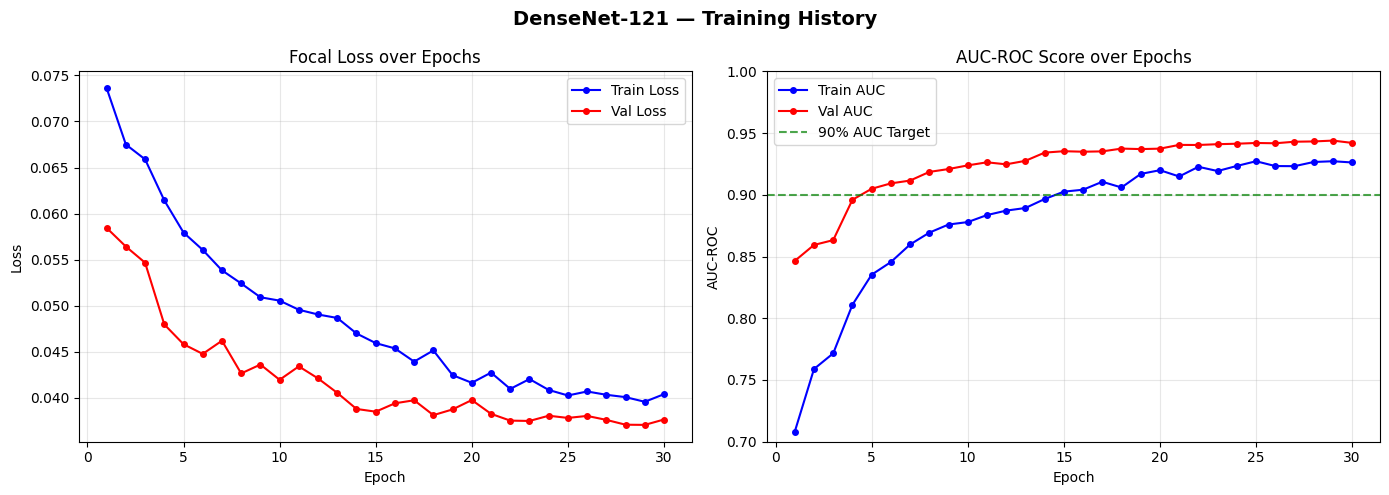

In [11]:
# ── CODE CELL 9: Training Curves ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DenseNet-121 — Training History', fontsize=14, fontweight='bold')
epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(epochs_ran, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Focal Loss over Epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['train_auc'], 'b-o', label='Train AUC', markersize=4)
axes[1].plot(epochs_ran, history['val_auc'],   'r-o', label='Val AUC',   markersize=4)
axes[1].axhline(y=0.90, color='green', linestyle='--', alpha=0.7, label='90% AUC Target')
axes[1].set_title('AUC-ROC Score over Epochs')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC-ROC')
axes[1].legend(); axes[1].grid(alpha=0.3); axes[1].set_ylim([0.7, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'densenet121_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## Test Set Evaluation

In [12]:
# ── CODE CELL 10: Final Evaluation with 3-View TTA (FIXED) ─────────────────
checkpoint = torch.load(SAVE_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"✅ Best checkpoint loaded (epoch {checkpoint['epoch']}, Val AUC: {checkpoint['val_auc']:.4f})")

def predict_with_tta(model, loader, device):    
    model.eval()
    all_labels  = []
    all_probs_0 = []  
    all_probs_h = []  
    all_probs_v = []  

    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  TTA Inference", leave=False):
            images = images.to(device, non_blocking=True)
            meta   = meta.to(device, non_blocking=True) # ✅ FIXED: Shifted meta to GPU
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Passed `meta` to all view orientations
                logits_orig  = model(images, meta)
                logits_hflip = model(torch.flip(images, dims=[3]), meta)
                logits_vflip = model(torch.flip(images, dims=[2]), meta)

            all_probs_0.extend(torch.sigmoid(logits_orig).cpu().numpy())
            all_probs_h.extend(torch.sigmoid(logits_hflip).cpu().numpy())
            all_probs_v.extend(torch.sigmoid(logits_vflip).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    import numpy as np
    probs_0 = np.array(all_probs_0)
    probs_h = np.array(all_probs_h)
    probs_v = np.array(all_probs_v)

    tta_probs = (probs_0 + probs_h + probs_v) / 3.0
    tta_labels = np.array(all_labels)
    tta_preds  = (tta_probs >= 0.5).astype(int)
    tta_auc    = roc_auc_score(tta_labels, tta_probs)
    tta_acc    = (tta_preds == tta_labels).mean()

    return tta_auc, tta_acc, tta_labels, tta_probs, tta_preds

test_auc, test_acc, test_labels, test_probs, test_preds = predict_with_tta(
    model, test_loader, DEVICE)

print("\n" + "=" * 60)
print("  DENSENET-121 — TEST SET RESULTS (3-View TTA)")
print("=" * 60)
print(f"\n  AUC-ROC  : {test_auc:.4f}")
print(f"  Accuracy : {test_acc:.4f}")
print("\n  Classification Report:")
print(classification_report(test_labels, test_preds,
                             target_names=['Benign (0)', 'Malignant (1)'], digits=4))


✅ Best checkpoint loaded (epoch 29, Val AUC: 0.9439)



  DENSENET-121 — TEST SET RESULTS (3-View TTA)

  AUC-ROC  : 0.9461
  Accuracy : 0.8788

  Classification Report:
               precision    recall  f1-score   support

   Benign (0)     0.8692    0.9513    0.9084      1600
Malignant (1)     0.9004    0.7548    0.8212       934

     accuracy                         0.8788      2534
    macro avg     0.8848    0.8530    0.8648      2534
 weighted avg     0.8807    0.8788    0.8762      2534



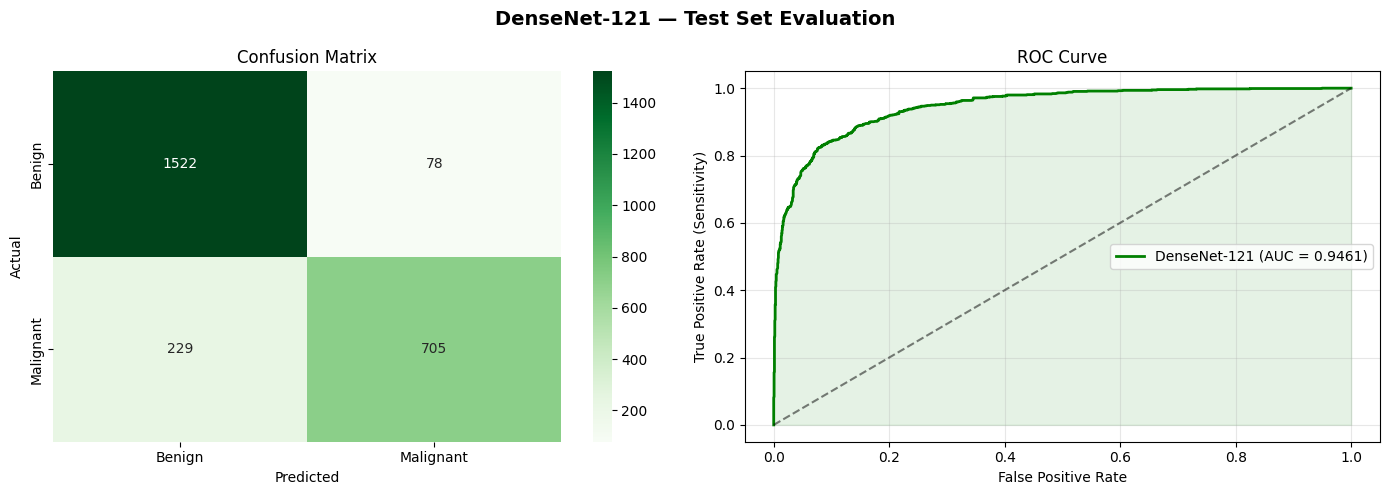

✅ Predictions saved for ensemble notebook.


In [13]:
# ── CODE CELL 11: Confusion Matrix & ROC ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DenseNet-121 — Test Set Evaluation', fontsize=14, fontweight='bold')

cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(test_labels, test_probs)
axes[1].plot(fpr, tpr, 'g-', linewidth=2,
             label=f'DenseNet-121 (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].fill_between(fpr, tpr, alpha=0.1, color='green')
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Sensitivity)')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'densenet121_evaluation.png'), dpi=150, bbox_inches='tight')
plt.show()

# Save predictions for Notebook 5
np.save(os.path.join(OUTPUT_DIR, 'densenet121_test_probs.npy'),  np.array(test_probs))
np.save(os.path.join(OUTPUT_DIR, 'densenet121_test_labels.npy'), np.array(test_labels))
print("✅ Predictions saved for ensemble notebook.")


In [14]:
# ── CODE CELL 12: Save Val & Test Probs for Stacking Ensemble (FIXED) ──────────
model.eval()
val_probs_tta  = [[], [], []]   
val_labels_all = []

with torch.no_grad():
    for images, meta, labels in tqdm(val_loader, desc='  Val TTA', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        meta   = meta.to(DEVICE, non_blocking=True) # ✅ FIXED: Shifted meta to GPU
        labels = labels.to(DEVICE, non_blocking=True)
        
        with torch.amp.autocast('cuda'):
            # ✅ FIXED: Passed `meta` consistently
            val_probs_tta[0].extend(torch.sigmoid(model(images, meta)).cpu().numpy())
            val_probs_tta[1].extend(torch.sigmoid(model(torch.flip(images, dims=[3]), meta)).cpu().numpy())
            val_probs_tta[2].extend(torch.sigmoid(model(torch.flip(images, dims=[2]), meta)).cpu().numpy())
            
        val_labels_all.extend(labels.cpu().numpy())

val_probs  = (np.array(val_probs_tta[0]) + np.array(val_probs_tta[1]) + np.array(val_probs_tta[2])) / 3.0
val_labels = np.array(val_labels_all)

np.save(os.path.join(OUTPUT_DIR, 'densenet121_val_probs.npy'),   val_probs)
np.save(os.path.join(OUTPUT_DIR, 'densenet121_val_labels.npy'),  val_labels)

print('✅ All outputs saved for Stacking Ensemble:')
print(f'   densenet121_test_probs.npy   — {len(test_probs)} predictions')
print(f'   densenet121_val_probs.npy    — {len(val_probs)} predictions (for meta-learner)')
print(f'   densenet121_best.pth         — best model weights')

✅ All outputs saved for Stacking Ensemble:
   densenet121_test_probs.npy   — 2534 predictions
   densenet121_val_probs.npy    — 2533 predictions (for meta-learner)
   densenet121_best.pth         — best model weights
